# III. Fundamentos del Modelamiento Predictivo
# Capítulo 7 - Introducción al Aprendizaje Computacional (Ejercicios)

<div style="border-top: 20px solid #b6effb; border-bottom: 20px solid #b6effb; background-color: #cff4fc; color: #055160;">

En los siguientes ejercicios vamos a profundizar en cómo aprende a pronosticar un modelo basado en el algoritmo de **Árbol de Decisión**. En concreto desarrollaremos el proceso lógico que se lleva a cabo para la definición de nodos, y sus correspondientes umbrales, a partir del uso de criterios de similitud como el *Índice de Gini*.

Con este objetivo llevaremos a cabo un proyecto en el cual entenderemos los datos con los que vamos a trabajar para a partir de allí construir un *árbol de decisión* sencillo de dos nodos para ejecutar una clasificación consistente y relativamente asertiva.

Vale señalar que como científico de datos, es especialmente valioso conocer qué sucede por detrás de las técnicas de modelamiento que empleamos, a fin de desarrollar una mayor capacidad analítica e interpretativa de los resultados que se alcanzan en los distintos proyectos. Así también, esto nos ayuda a perfeccionar nuestras capacidades técnicas en la escritura de nuevos algoritmos que en el futuro podamos crear.

</div>

## Entendimiento del contexto

Has sido contratado por la cadena televisiva ESPN para colaborar en el desarrollo de un modelo predictivo basado en técnicas de Machine Learning, cuyo objetivo es estimar la probabilidad de que un jugador de la NBA consiga una renovación de su contrato con su equipo actual. Para ello, se dispone de información relacionada con su rendimiento deportivo y las condiciones económicas de sus contratos vigentes.

El propósito del modelo es identificar patrones y relaciones respecto a las decisiones de renovación contractual tomadas por los equipos. En particular, se busca determinar en qué medida el rendimiento individual y el costo salarial de un jugador pueden influir en la decisión de una franquicia de mantenerlo dentro de su plantilla. De esta manera, el modelo deberá aprender a partir de los antecedentes históricos para clasificar a los jugadores actuales respecto a la posibilidad de obtener una renovación contractual, considerando que un buen rendimiento deportivo no necesariamente garantiza la continuidad de un jugador, especialmente cuando sus expectativas salariales o el costo de su contrato no se corresponden con el valor que aporta al equipo.

ESPN considera que esta herramienta analítica representará un aporte significativo para enriquecer sus espacios de opinión y análisis deportivo, particularmente aquellos conducidos por periodistas y comentaristas especializados en la NBA. Contar con estimaciones respaldadas por evidencia estadística permitirá complementar la investigación periodística tradicional y ofrecer argumentos más objetivos al momento de debatir sobre el futuro contractual de determinados jugadores. Así, el modelo no pretende sustituir el criterio de los periodistas ni anticipar con certeza las decisiones de las franquicias, sino proporcionar una perspectiva adicional, fundamentada en datos, que contribuya a generar análisis más rigurosos, identificar posibles escenarios y enriquecer la discusión deportiva.

## Entendimiento de los datos

### Ejercicio 1

Importa las librerías **pandas** y **matplotlib**, así como el módulo `stats` de **scipy**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st

ESPN ha compartido contigo la siguiente información histórica respecto a 40 jugadores activos de la NBA:

* Total de puntos marcados en los últimos 6 encuentros disputados en la temporada regular que acaba de finalizar.

* Salario actual percibido por el jugador en dicha temporada en millones de USD.

* Indicador si al jugador el equipo le renovó el contrato (1) o no (0).

```py
{
    "puntos": [
        140,190,110,140,142,120,160,160,60,190,
        52,60,160,60,70,140,170,140,109,180,
        140,139,90,90,170,90,90,50,120,140,
        120,40,70,131,110,40,70,55,50,160
    ],
    "salario": [
        2.6,6.1,5.8,4.8,3.6,4.0,2.8,4.5,3.7,5.5,
        1.9,6.2,5.1,5.9,2.7,1.9,4.7,5.8,6.4,3.7,
        5.5,3.0,3.9,5.9,2.2,2.7,5.7,1.9,3.8,3.9,
        5.3,5.1,3.4,2.1,1.9,5.7,5.1,4.2,2.2,5.9
    ],
    "renovacion": [
        1,0,1,1,1,0,1,1,0,0,
        1,0,0,0,1,1,0,1,0,0,
        0,1,0,0,1,1,0,0,0,1,
        1,0,0,1,1,0,1,0,1,0
    ]
}
```

Guarda esta información en un dataset mediante la función `pd.DataFrame` y mira su estructura general.

In [2]:
# Cargar diccionario de datos
dicc_renovacion = {
    "puntos": [
        140,190,110,140,142,120,160,160,60,190,
        52,60,160,60,70,140,170,140,109,180,
        140,139,90,90,170,90,90,50,120,140,
        120,40,70,131,110,40,70,55,50,160
    ],
    "salario": [
        2.6,6.1,5.8,4.8,3.6,4.0,2.8,4.5,3.7,5.5,
        1.9,6.2,5.1,5.9,2.7,1.9,4.7,5.8,6.4,3.7,
        5.5,3.0,3.9,5.9,2.2,2.7,5.7,1.9,3.8,3.9,
        5.3,5.1,3.4,2.1,1.9,5.7,5.1,4.2,2.2,5.9
    ],
    "renovacion": [
        1,0,1,1,1,0,1,1,0,0,
        1,0,0,0,1,1,0,1,0,0,
        0,1,0,0,1,1,0,0,0,1,
        1,0,0,1,1,0,1,0,1,0
    ]
}

# Convertir a dataframe
df_renovacion = pd.DataFrame(dicc_renovacion)

# Mirar estructura de los datos
df_renovacion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   puntos      40 non-null     int64  
 1   salario     40 non-null     float64
 2   renovacion  40 non-null     int64  
dtypes: float64(1), int64(2)
memory usage: 1.1 KB


### Ejercicio 2

Explora esta información mediante una muestra de los datos y resúmenes estadísticos de las variables existentes.

In [3]:
# Generar muestra de los datos
df_renovacion.sample(10)

,puntos,salario,renovacion
15,140,1.9,1
28,120,3.8,0
2,110,5.8,1
0,140,2.6,1
18,109,6.4,0
5,120,4.0,0
32,70,3.4,0
23,90,5.9,0
25,90,2.7,1
24,170,2.2,1


In [4]:
# Estudiar la distribucion estadistica de atributos
df_renovacion[["puntos", "salario"]].describe().round(2)

,puntos,salario
count,40.00,40.00
mean,112.95,4.18
std,45.25,1.47
min,40.00,1.90
25%,70.00,2.78
50%,120.00,4.10
75%,140.50,5.55
max,190.00,6.40


In [5]:
# Contar casos por las clases objetivo
df_renovacion["renovacion"].value_counts()

renovacion
0    21
1    19
Name: count, dtype: int64

Estudia la relación existente en los atributos y la variable objetivo (renovacion).

In [6]:
# Estimar el valor promedio de atributos por clase de variable objetivo
df_renovacion.groupby("renovacion").mean().round(2)

,puntos,salario
renovacion,,
0,106.86,4.87
1,119.68,3.41


In [7]:
# Calcular correlacion biserial entre renovacion y puntos
corr_biserial = st.pointbiserialr(df_renovacion["renovacion"], df_renovacion["puntos"]).statistic
print(f"Correlación entre puntos y renovacion: {corr_biserial:.1%}")

Correlación entre puntos y renovacion: 14.3%


In [8]:
# Calcular correlacion biserial entre renovacion y salario
corr_biserial = st.pointbiserialr(df_renovacion["renovacion"], df_renovacion["salario"]).statistic
print(f"Correlación entre salario y renovacion: {corr_biserial:.1%}")

Correlación entre salario y renovacion: -50.2%


Si todo fue realizado correctamente podrás evidenciar que el salario tiene una relación significativa (aunque negativa) con la variable objetivo. Por lo tanto la usaremos como atributo de nuestro *árbol de decisión* sencillo.

## Creación de primer nodo del modelo

### Ejercicio 1

El **Índice de Gini** ($G$) es un criterio de similitud muy utilizado para la creación de nodos dentro del algoritmo de **árbol de decisión**. El mismo se define por la siguiente igualdad:

$$ G = 1 - \sum_{i=1}^{K} p_i^2 $$

donde $K$ corresponde al número de clases posibles de la variable objetivo y $p_i$ es la proporción que representa la $i$-ésima de estas clases en la totalidad de los datos disponibles.

Dada esta definición calcula el valor del Índice de Gini de los datos con los que estamos trabajando, y guarda este resultado en la variable `gini_inicial`.

In [9]:
gini_inicial = 1 - sum(df_renovacion["renovacion"].value_counts(normalize = True) ** 2)
print(f"Gini inicial: {gini_inicial:.1%}")

Gini inicial: 49.9%


<div class="alert alert-info">

El Índice de Gini toma valores entre 0% y 50% tal que el límite inferior representa una completa similitud de los datos respecto a la variable objetivo estudiada, esto es, todos los elementos observados en dicha variable serían los mismos (i.e renovacion). El límite superior por su parte da cuenta de la existencia de una cantidad de elementos de una clase en la misma proporción que los de la otra, es decir, una completa disparidad.

El resultado que obtuviste justamente es muy cercano a 50% ya que contamos con casi la misma proporción de casos de renovación, con aquellos que no presentan esta cualidad.

</div>

### Ejercicio 2

Ahora bien, para una adecuada creación de un nodo debemos definir un umbral adecuado para el atributo salario, tal que los nodos resultantes generen resultados de $G$ menores. De hecho estos valores deberían idealmente ser lo más bajos posibles. 

Con este objetivo, crea un dataframe `df_eval` que contenga los valores únicos de salarios encontrados en nuestros datos.

In [10]:
df_eval = pd.DataFrame(dict(
    salario = sorted(df_renovacion["salario"].unique())
))
df_eval

,salario
0,1.9
1,2.1
2,2.2
3,2.6
4,2.7
5,2.8
6,3.0
7,3.4
8,3.6
9,3.7


Supongamos que definimos a cada uno de estos valores como un candidato a umbral. Incorpora en este dataframe una columna llamada *casos_verdaderos* con el conteo de observaciones que son menores o iguales a cada uno de los salarios únicos registrados.

In [11]:
df_eval["casos_verdaderos"] = (
    df_eval["salario"]
    .apply(lambda x: sum(df_renovacion["salario"] <= x))
)
df_eval

,salario,casos_verdaderos
0,1.9,4
1,2.1,5
2,2.2,7
3,2.6,8
4,2.7,10
5,2.8,11
6,3.0,12
7,3.4,13
8,3.6,14
9,3.7,16


A modo de validación, en esta columna se debería por ejemplo evidenciar que existen 17 registros de jugadores menores o iguales a un salario de 3.8 millones.

Crea ahora la columna *prop_verdaderos* en la que se muestre para cada salario único la proporción de renovaciones existentes entre los casos verdaderos establecidos.

In [12]:
df_eval["prop_verdaderos"] = (
    df_eval["salario"]
    .apply(lambda x: df_renovacion[df_renovacion["salario"] <= x]["renovacion"].mean())
)
df_eval

,salario,casos_verdaderos,prop_verdaderos
0,1.9,4,0.750000
1,2.1,5,0.800000
2,2.2,7,0.857143
3,2.6,8,0.875000
4,2.7,10,0.900000
5,2.8,11,0.909091
6,3.0,12,0.916667
7,3.4,13,0.846154
8,3.6,14,0.857143
9,3.7,16,0.750000


Considerando que la proporción de casos que no serían renovación es el complemento del último resultado obtenido tal que

$$ p_{(No\;Renovacion)} = 1 - p_{(Renovacion)} $$

Calcula el valor del Índice de Gini correspondiente a cada candidato a umbral del salario. Guarda estos resultados en la columna *gini_verdaderos*.

In [13]:
df_eval["gini_verdaderos"] = 1 - (df_eval["prop_verdaderos"]**2 + (1 - df_eval["prop_verdaderos"])**2)
df_eval

,salario,casos_verdaderos,prop_verdaderos,gini_verdaderos
0,1.9,4,0.750000,0.375000
1,2.1,5,0.800000,0.320000
2,2.2,7,0.857143,0.244898
3,2.6,8,0.875000,0.218750
4,2.7,10,0.900000,0.180000
5,2.8,11,0.909091,0.165289
6,3.0,12,0.916667,0.152778
7,3.4,13,0.846154,0.260355
8,3.6,14,0.857143,0.244898
9,3.7,16,0.750000,0.375000


¿Qué implica este resultado? Si por ejemplo consideramos un umbral de salario de 3.8 millones, entonces el nodo del *árbol de decisión* que se generaría con todos los casos menores o iguales a este valor alcanzaría un $G \approx 41.5\%$, dado que el 70.6% de dichos casos corresponden a la clase renovación.

### Ejercicio 3

Repite el mismo procedimiento del ejercicio anterior para obtener el Índice de Gini de cada posible candidato de umbrales de salario en los casos donde las observaciones sean mayores al mismo. Genera las columnas adicionales que correspondan en `df_eval`. 

In [14]:
# Incorporar conteo de casos mayores a umbral
df_eval["casos_falsos"] = (
    df_eval["salario"]
    .apply(lambda x: sum(df_renovacion["salario"] > x))
)

In [15]:
# Incorporar proporcion de renovaciones
df_eval["prop_falsos"] = (
    df_eval["salario"]
    .apply(lambda x: df_renovacion[df_renovacion["salario"] > x]["renovacion"].mean())
)

In [16]:
# Calcular gini asociado
df_eval["gini_falsos"] = 1 - (df_eval["prop_falsos"]**2 + (1 - df_eval["prop_falsos"])**2)
df_eval

,salario,casos_verdaderos,prop_verdaderos,gini_verdaderos,casos_falsos,prop_falsos,gini_falsos
0,1.9,4,0.750000,0.375000,36,0.444444,0.493827
1,2.1,5,0.800000,0.320000,35,0.428571,0.489796
2,2.2,7,0.857143,0.244898,33,0.393939,0.477502
3,2.6,8,0.875000,0.218750,32,0.375000,0.468750
4,2.7,10,0.900000,0.180000,30,0.333333,0.444444
5,2.8,11,0.909091,0.165289,29,0.310345,0.428062
6,3.0,12,0.916667,0.152778,28,0.285714,0.408163
7,3.4,13,0.846154,0.260355,27,0.296296,0.417010
8,3.6,14,0.857143,0.244898,26,0.269231,0.393491
9,3.7,16,0.750000,0.375000,24,0.291667,0.413194


Imputa los valores ausentes que hayan surgido con el valor de 0.

In [17]:
df_eval = df_eval.fillna(0)
df_eval

,salario,casos_verdaderos,prop_verdaderos,gini_verdaderos,casos_falsos,prop_falsos,gini_falsos
0,1.9,4,0.750000,0.375000,36,0.444444,0.493827
1,2.1,5,0.800000,0.320000,35,0.428571,0.489796
2,2.2,7,0.857143,0.244898,33,0.393939,0.477502
3,2.6,8,0.875000,0.218750,32,0.375000,0.468750
4,2.7,10,0.900000,0.180000,30,0.333333,0.444444
5,2.8,11,0.909091,0.165289,29,0.310345,0.428062
6,3.0,12,0.916667,0.152778,28,0.285714,0.408163
7,3.4,13,0.846154,0.260355,27,0.296296,0.417010
8,3.6,14,0.857143,0.244898,26,0.269231,0.393491
9,3.7,16,0.750000,0.375000,24,0.291667,0.413194


Retomando nuestro ejemplo del candidato a umbral de 3.8 millones, el potencial nodo generado con casos mayores dará como resultado $G \approx 42.3\%$ dada una proporción de renovaciones del 30.4%.

### Ejercicio 4

Para seleccionar el mejor umbral posible convendría tomar aquel que en promedio genere nodos "verdadero" y "falso" con el Índice de Gini más bajo. Por tanto, calcula el promedio ponderado de cada candidato de salario tal que

$$ G_{prom} = \frac{n_{v}}{n_{v} + n_{f}}G_{v} + \frac{n_{f}}{n_{v} + n_{f}}G_{f}$$

donde $n_v$ y $n_f$ corresponden a los valores de las columnas casos_verdaderos y casos_falsos respectivamente. Guarda estos resultados en la columna *gini_promedio*.

In [18]:
df_eval["gini_promedio"] = (df_eval["casos_verdaderos"] * df_eval["gini_verdaderos"] + df_eval["casos_falsos"] * df_eval["gini_falsos"]) / (df_eval["casos_verdaderos"] + df_eval["casos_falsos"])
df_eval

,salario,casos_verdaderos,prop_verdaderos,gini_verdaderos,casos_falsos,prop_falsos,gini_falsos,gini_promedio
0,1.9,4,0.750000,0.375000,36,0.444444,0.493827,0.481944
1,2.1,5,0.800000,0.320000,35,0.428571,0.489796,0.468571
2,2.2,7,0.857143,0.244898,33,0.393939,0.477502,0.436797
3,2.6,8,0.875000,0.218750,32,0.375000,0.468750,0.418750
4,2.7,10,0.900000,0.180000,30,0.333333,0.444444,0.378333
5,2.8,11,0.909091,0.165289,29,0.310345,0.428062,0.355799
6,3.0,12,0.916667,0.152778,28,0.285714,0.408163,0.331548
7,3.4,13,0.846154,0.260355,27,0.296296,0.417010,0.366097
8,3.6,14,0.857143,0.244898,26,0.269231,0.393491,0.341484
9,3.7,16,0.750000,0.375000,24,0.291667,0.413194,0.397917


Visualiza mediante un gráfico de líneas el comportamiento de este Índice de Gini promedio con relación a los posibles salarios candidatos.

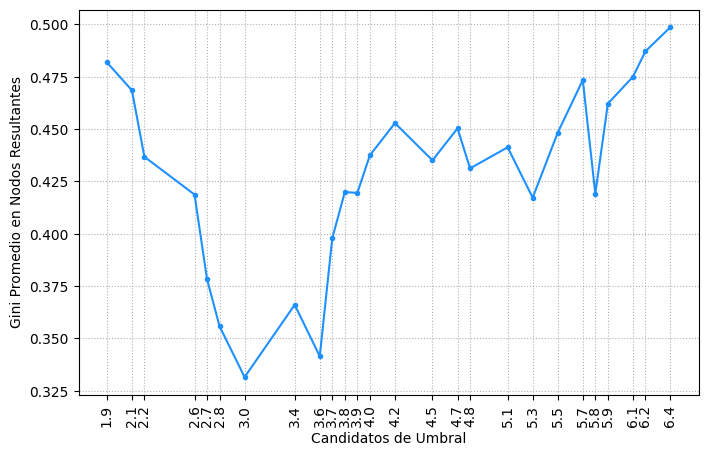

In [19]:
df_eval.plot(
    kind = "line",
    figsize = [8,5],
    x = "salario",
    y = "gini_promedio",
    color = "dodgerblue",
    marker = ".",
    legend = None,
    xlabel = "Candidatos de Umbral",
    ylabel = "Gini Promedio en Nodos Resultantes",
    rot = 90
)
plt.xticks(df_eval["salario"])
plt.grid(linestyle = ":")
plt.show()

Si todo se ha realizado de manera correcta entonces resulta claro que el umbral a seleccionar es **3.0**, tal que la regla de decisión del primer nodo estaría dada por:

```
IF salario <= 3
--->TRUE
    renovacion == 1 (Prob = 0.9167)
--->FALSE
    renovacion == 0 (Prob = 0.7143)
```

Observa los resultados alcanzados en las columnas de `df_eval` para interpretar estos valores alcanzados.

<div class="alert alert-info">

Para la determinación del primer nodo hemos empleado como medida de similitud al Índice de Gini, sin embargo existen otras formas de establecer un criterio, siendo una de las más comunes la denominada **Entropía** ($H$). Esta medida surge de un indicador conocido como *Impureza de Shannon*, y para cada nodo se la estima igualmente a partir de las proporciones de las clases en la variable objetivo tal que

$$ H = -\sum_{i=1}^{K} p_i\log_2(p_i) $$

La entropía puede encontrarse entre 0 y $\log_2(K)$, donde el límite inferior representa una completa similitud, y el superior una completa disparidad en el nodo evaluado. 

</div>

## Creación de segundo nodo del modelo

### Ejercicio 1

En nuestro modelo actual podemos notar que cuando el salario es mayor al umbral de 3.0 entonces se decide que no existe una renovación con probabilidad de 71.4%. Construyamos un nodo adicional aquí para intentar incrementar este grado de asertividad.

Filtra el dataset de observaciones para mantener únicamente los 28 casos que cumplen este criterio (salario mayor a 3.0).

In [20]:
df_filtrado = df_renovacion.query("salario > 3")
df_filtrado.shape

(28, 3)

A partir de esta tabla filtrada crea nuevamente un dataframe `df_eval` pero que ahora contenga los valores únicos de la variable puntos.

In [21]:
df_eval = pd.DataFrame(dict(
    puntos = sorted(df_filtrado["puntos"].unique())
))
df_eval

,puntos
0,40
1,55
2,60
3,70
4,90
5,109
6,110
7,120
8,140
9,142


Estos valores únicos se constituyen ahora en umbrales candidatos para el nuevo nodo.

### Ejercicio 2

Ejecuta el procedimiento visto en el apartado anterior para determinar el Índice de Gini alcanzado para la opción "verdaderos" dados estos candidatos a umbrales de la variable puntos.

In [22]:
# Incorporar conteo de casos menores o iguales a umbral
df_eval["casos_verdaderos"] = (
    df_eval["puntos"]
    .apply(lambda x: sum(df_filtrado["puntos"] <= x))
)

In [23]:
# Incorporar proporcion de renovaciones
df_eval["prop_verdaderos"] = (
    df_eval["puntos"]
    .apply(lambda x: df_filtrado[df_filtrado["puntos"] <= x]["renovacion"].mean())
)

In [24]:
# Calcular gini asociado
df_eval["gini_verdaderos"] = 1 - (df_eval["prop_verdaderos"]**2 + (1 - df_eval["prop_verdaderos"])**2)
df_eval

,puntos,casos_verdaderos,prop_verdaderos,gini_verdaderos
0,40,2,0.000000,0.000000
1,55,3,0.000000,0.000000
2,60,6,0.000000,0.000000
3,70,8,0.125000,0.218750
4,90,11,0.090909,0.165289
5,109,12,0.083333,0.152778
6,110,13,0.153846,0.260355
7,120,16,0.187500,0.304688
8,140,20,0.300000,0.420000
9,142,21,0.333333,0.444444


Ejecuta el procedimiento para obtener la columna *gini_falsos*. Recuerda imputar valores perdidos por 0 en caso que aparezcan. 

In [25]:
# Incorporar conteo de casos mayores a umbral
df_eval["casos_falsos"] = (
    df_eval["puntos"]
    .apply(lambda x: sum(df_filtrado["puntos"] > x))
)

In [26]:
# Incorporar proporcion de renovaciones
df_eval["prop_falsos"] = (
    df_eval["puntos"]
    .apply(lambda x: df_filtrado[df_filtrado["puntos"] > x]["renovacion"].mean())
)

In [27]:
# Calcular gini asociado
df_eval["gini_falsos"] = 1 - (df_eval["prop_falsos"]**2 + (1 - df_eval["prop_falsos"])**2)
df_eval

,puntos,casos_verdaderos,prop_verdaderos,gini_verdaderos,casos_falsos,prop_falsos,gini_falsos
0,40,2,0.000000,0.000000,26,0.307692,0.426036
1,55,3,0.000000,0.000000,25,0.320000,0.435200
2,60,6,0.000000,0.000000,22,0.363636,0.462810
3,70,8,0.125000,0.218750,20,0.350000,0.455000
4,90,11,0.090909,0.165289,17,0.411765,0.484429
5,109,12,0.083333,0.152778,16,0.437500,0.492188
6,110,13,0.153846,0.260355,15,0.400000,0.480000
7,120,16,0.187500,0.304688,12,0.416667,0.486111
8,140,20,0.300000,0.420000,8,0.250000,0.375000
9,142,21,0.333333,0.444444,7,0.142857,0.244898


In [28]:
# Imputar valores perdidos con 0
df_eval = df_eval.fillna(0)
df_eval

,puntos,casos_verdaderos,prop_verdaderos,gini_verdaderos,casos_falsos,prop_falsos,gini_falsos
0,40,2,0.000000,0.000000,26,0.307692,0.426036
1,55,3,0.000000,0.000000,25,0.320000,0.435200
2,60,6,0.000000,0.000000,22,0.363636,0.462810
3,70,8,0.125000,0.218750,20,0.350000,0.455000
4,90,11,0.090909,0.165289,17,0.411765,0.484429
5,109,12,0.083333,0.152778,16,0.437500,0.492188
6,110,13,0.153846,0.260355,15,0.400000,0.480000
7,120,16,0.187500,0.304688,12,0.416667,0.486111
8,140,20,0.300000,0.420000,8,0.250000,0.375000
9,142,21,0.333333,0.444444,7,0.142857,0.244898


Calcula el Índice de Gini Promedio para identificar el umbral que minimizaría el valor resultante.

In [29]:
# Calcular el gini promedio por umbral
df_eval["gini_promedio"] = (df_eval["casos_verdaderos"] * df_eval["gini_verdaderos"] + df_eval["casos_falsos"] * df_eval["gini_falsos"]) / (df_eval["casos_verdaderos"] + df_eval["casos_falsos"])
df_eval

,puntos,casos_verdaderos,prop_verdaderos,gini_verdaderos,casos_falsos,prop_falsos,gini_falsos,gini_promedio
0,40,2,0.000000,0.000000,26,0.307692,0.426036,0.395604
1,55,3,0.000000,0.000000,25,0.320000,0.435200,0.388571
2,60,6,0.000000,0.000000,22,0.363636,0.462810,0.363636
3,70,8,0.125000,0.218750,20,0.350000,0.455000,0.387500
4,90,11,0.090909,0.165289,17,0.411765,0.484429,0.359053
5,109,12,0.083333,0.152778,16,0.437500,0.492188,0.346726
6,110,13,0.153846,0.260355,15,0.400000,0.480000,0.378022
7,120,16,0.187500,0.304688,12,0.416667,0.486111,0.382440
8,140,20,0.300000,0.420000,8,0.250000,0.375000,0.407143
9,142,21,0.333333,0.444444,7,0.142857,0.244898,0.394558


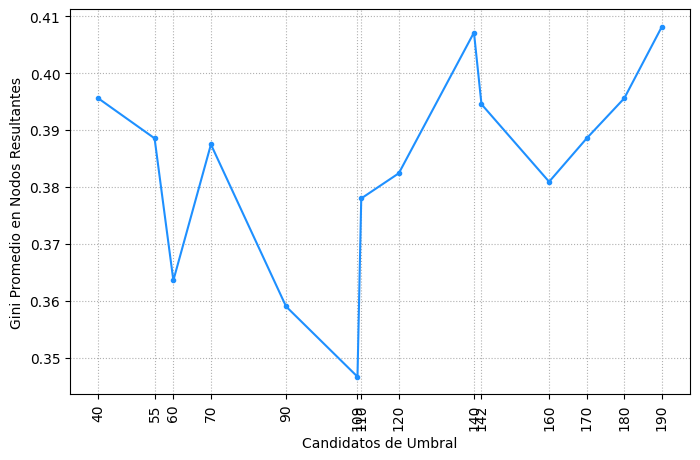

In [30]:
# Visualizar gini por umbral
df_eval.plot(
    kind = "line",
    figsize = [8,5],
    x = "puntos",
    y = "gini_promedio",
    color = "dodgerblue",
    marker = ".",
    legend = None,
    xlabel = "Candidatos de Umbral",
    ylabel = "Gini Promedio en Nodos Resultantes",
    rot = 90
)
plt.xticks(df_eval["puntos"])
plt.grid(linestyle = ":")
plt.show()

Ante estos resultados se obtiene que con un umbral de **109** puntos se alcanza un óptimo, tal que el árbol de decisión quedaría definido de la siguiente forma:

```
IF salario <= 3
--->TRUE
    renovacion == 1 (Prob = 0.9167)
--->FALSE
    IF puntos <= 109
    --->TRUE
        renovacion == 0 (Prob = 0.9167)
    --->FALSE
        renovacion == 1 (Prob = 0.4375)
```

### Ejercicio 3

Evaluemos que tan bien clasifica nuestro modelo simple creado. Para ello en primer lugar crea una función que devuelva si se dará una renovación o no a partir de los valores de salario y puntos del dataframe inicial y tomando en consideración la lógica del modelo creado.

In [31]:
def fun_modelo (row):

    if row["salario"] <= 3:
        return 1
    elif row["puntos"] <= 109:
        return 0
    else:
        return 1

Aplica esta función para crear una nueva columna llamada *predicción* en la que se pronostique si se dará o no una renovación. 

In [32]:
df_renovacion["prediccion"] = df_renovacion.apply(fun_modelo, axis = 1)
df_renovacion.sample(5)

,puntos,salario,renovacion,prediccion
23,90,5.9,0,0
8,60,3.7,0,0
32,70,3.4,0,0
36,70,5.1,1,0
17,140,5.8,1,1


Crea una matriz de confusión para contrastar esta predicción con los valores reales y evaluar así el rendimiento del modelo.

In [33]:
mat_conf = pd.crosstab(
    index = df_renovacion["renovacion"],
    columns = df_renovacion["prediccion"],
    margins = True,
    rownames = ["Reales"],
    colnames = ["Predichos"]
)
print(mat_conf)

Predichos   0   1  All
Reales                
0          11  10   21
1           1  18   19
All        12  28   40


A partir de los valores de esta matriz, calcula la exactitud alcanzada por tu modelo.

In [34]:
exactitud = (11 + 18) / 40
print(f"Exactitud: {exactitud:.1%}")

Exactitud: 72.5%
